# 8. AUTO on maps

AUTO on discrete maps: the logistic map  x -> r x (1 - x).

```text
  fixed point x* = 1 - 1/r loses stability (multiplier -1) at r = 3,
  the period-2 orbit loses stability at r = 1 + sqrt(6) = 3.4495     [derivation]
```

AUTO follows fixed points.  To follow the period-2 orbit, follow fixed
points of the second iterate f(f(x)) instead.  XPP's AUTO reports a
multiplier leaving the unit circle with the label "HB", also when the
multiplier is -1 (a flip / period doubling), as here.

The background is the usual orbit diagram from simulation (sweep r,
keep the last iterates).  The script version writes auto_maps.png.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import pyxpp

# `meth=discrete` makes XPP iterate x(t+1) = ...; AUTO then treats the
# system as a map (no start menu: a map run is always a fixed-point run).
f1 = pyxpp.load(text="""
x(t+1)=r*x*(1-x)
par r=2.5
init x=0.3
@ total=300, meth=discrete
done
""")

## orbit diagram by simulation

In [2]:
rs = np.linspace(2.5, 4.0, 600)
fig, ax = plt.subplots(figsize=(8, 5))
plt.close(fig)  # drawn into below, shown at the end
for tr, r in zip(f1.sweep("r", rs), rs):
    ax.plot(np.full(100, r), tr["x"][-100:], ",", color="0.6")

## fixed points of f

In [3]:
f1.pars["r"] = 2.5
f1.run()
f1.run_last()
br1 = f1.auto.run("r", start="steady", ds=0.01, dsmax=0.02, parmin=2.5, parmax=4, nmax=200)
flip1 = br1.special("HB")[0]
print(f"f:   loses stability at r = {flip1.x:.6f} (exact 3)")

f:   loses stability at r = 3.000034 (exact 3)


## fixed points of f(f(x)), started on the period-2 orbit at r = 3.2

In [4]:
f2 = pyxpp.load(text="""
f(u)=r*u*(1-u)
x(t+1)=f(f(x))
par r=3.2
init x=0.5
@ total=300, meth=discrete
done
""")
f2.run()
f2.run_last()
br2 = f2.auto.run("r", start="steady", ds=0.01, dsmax=0.02, parmin=2.9, parmax=4, nmax=200)
# and back down from the starting point, where the 2-cycle is born at r = 3.
# AUTO switches branches at that branch point onto the fixed point of f
# (also a fixed point of f∘f); keep only points where f(x) != x.
back = f2.auto.run(grab=br2[0].label, ds=-0.01)
two_cycle = [p for p in br2.points + back.points
             if abs(p.x * p.u0["x"] * (1 - p.u0["x"]) - p.u0["x"]) > 1e-4]
br2 = pyxpp.Diagram(sorted(two_cycle, key=lambda p: p.x), br2.vars)
flip2 = br2.special("HB")[0]
print(f"f^2: loses stability at r = {flip2.x:.6f} (exact {1 + np.sqrt(6):.6f})")

# the other point of the 2-cycle is f(x)
for br, col, lab in [(br1, "C3", "fixed point of f"), (br2, "C0", "2-cycle (fixed point of f∘f)")]:
    r = np.array([p.x for p in br])
    x = np.array([p.u0["x"] for p in br])
    st = np.array([p.stable for p in br])
    xs = [x] if br is br1 else [x, r * x * (1 - x)]
    for k, xx in enumerate(xs):
        ax.plot(np.where(st, r, np.nan), np.where(st, xx, np.nan), color=col, lw=2,
                label=lab if k == 0 else None)
        ax.plot(np.where(~st, r, np.nan), np.where(~st, xx, np.nan), "--", color=col, lw=1)
for p in (flip1, flip2):
    ax.axvline(p.x, color="k", lw=0.5)
ax.set(xlabel="r", ylabel="x", xlim=(2.5, 4), ylim=(0, 1),
       title="logistic map: AUTO branches over the orbit diagram (solid = stable)")
ax.legend(loc="lower left")
fig.tight_layout()

f^2: loses stability at r = 3.449496 (exact 3.449490)


## The figure

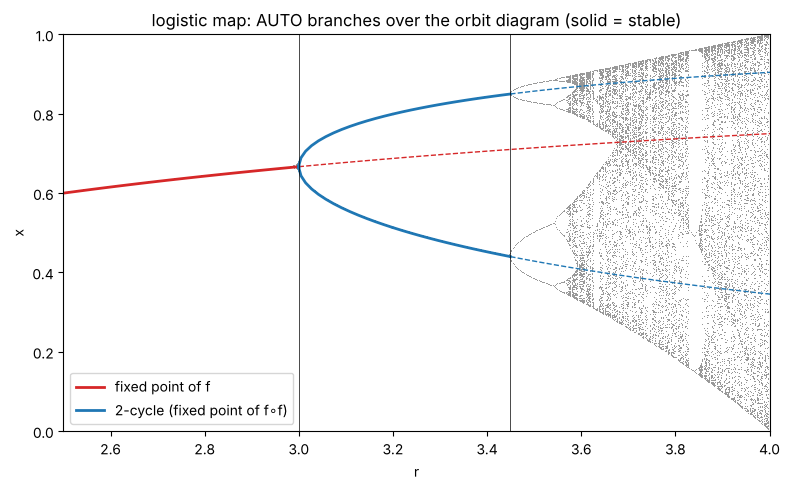

In [5]:
fig